In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Memuat Dataset
df_nasabah = pd.read_csv('nasabah_raw.csv')

In [2]:
# 1. Periksa dimensi awal dataset dan informasi tipe data tiap kolom
print("=== Dimensi Awal Dataset ===")
print("Jumlah Baris & Kolom:", df_nasabah.shape)
print("\n=== Informasi Tipe Data ===")
df_nasabah.info()

# 2. Identifikasi jumlah data duplikat penuh dan tampilkan sampel baris yang terduplikasi
jumlah_duplikat = df_nasabah.duplicated().sum()
print("\nJumlah data duplikat penuh: ", jumlah_duplikat)

if jumlah_duplikat > 0:
    print("\nSampel baris yang terduplikasi:")
    display(df_nasabah[df_nasabah.duplicated(keep=False)].head())

# Hapus seluruh duplikat penuh
df_nasabah = df_nasabah.drop_duplicates().copy()

# 3. Hitung sisa baris data setelah tahap penghapusan duplikat
sisa_baris = df_nasabah.shape[0]
print("\nSisa jumlah baris data setelah penghapusan duplikat:", sisa_baris, "baris")

=== Dimensi Awal Dataset ===
Jumlah Baris & Kolom: (1045, 9)

=== Informasi Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

Jumlah data duplikat penuh:  45

Sampel baris yang terduplikasi:


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN



Sisa jumlah baris data setelah penghapusan duplikat: 1000 baris


In [3]:
# 1. Periksa nilai unik Status_Pernikahan dan bersihkan format teks
print("Nilai unik Status_Pernikahan sebelum pembersihan:")
print(df_nasabah['Status_Pernikahan'].unique())

# Pembersihan format teks, hapus spasi di awal / akhir dan ubah menjadi Title Case
df_nasabah['Status_Pernikahan'] = (
    df_nasabah['Status_Pernikahan']
    .astype(str)
    .str.strip()
    .str.title()
)

print("\nNilai unik Status_Pernikahan setelah pembersihan:")
print(df_nasabah['Status_Pernikahan'].unique())

# 2. Pemeriksaan logis pada kolom Usia (ambang batas valid: 17 - 100 tahun)
# Nilai di luar batas logis diubah menjadi NaN
df_nasabah.loc[(df_nasabah['Usia'] < 17) | (df_nasabah['Usia'] > 100), 'Usia'] = np.nan

print(f"\nJumlah nilai NaN pada kolom Usia setelah pembersihan logis: {df_nasabah['Usia'].isna().sum()}")

Nilai unik Status_Pernikahan sebelum pembersihan:
['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']

Nilai unik Status_Pernikahan setelah pembersihan:
['Menikah' 'Single' 'Cerai']

Jumlah nilai NaN pada kolom Usia setelah pembersihan logis: 35


JAWABAN B-3:

Jika nilai Usia tidak dikoreksi kesalahannya, maka nilai anomali akan mengganggu proses perhitungan statistik dasar. Mean sangat sensitif terhadap data yang salah. Begitu juga dengan nilai median yang urutan nilainya akan bergeser. Mengosongkan data yang tidak valid memastikan penentuan nilai tengah didapatkan berdasarkan sebaran data yang valid.

In [4]:
# Memuat data kredit eksternal
df_eksternal = pd.read_csv('data_kredit_eksternal.csv')

# 1, 2. Penggabungan dengan metode Left Join berdasarkan 'ID_Pelanggan'
df_merged = pd.merge(df_nasabah, df_eksternal, on='ID_Pelanggan', how='left')

# 3. Tampilkan dimensi dataset setelah penggabungan
print("Dimensi dataset setelah penggabungan (Left Join):", df_merged.shape)
df_merged.head()

Dimensi dataset setelah penggabungan (Left Join): (1000, 11)


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0,Tidak,5.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0,Tidak,3.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0,Tidak,5.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0,Ya,6.0
4,CUST-1005,NaN,8295000.0,831.0,15.0,Single,SMA,0,99540000.0,Ya,4.0


In [5]:
# 1. Tampilkan persentase missing values untuk setiap kolom
persentase_missing = (df_merged.isnull().sum() / len(df_merged)) * 100
df_missing_info = pd.DataFrame({
    'Jumlah Missing': df_merged.isnull().sum(),
    'Persentase (%)': persentase_missing.round(2)
})
print("=== Persentase Missing Values per Kolom ===")
print(df_missing_info)

# 2. Penanganan missing values sesuai strategi
# 1). Kolom numerik kontinu: Isi dengan nilai Median
kolom_kontinu = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']
for col in kolom_kontinu:
    if col in df_merged.columns:
        median_val = df_merged[col].median()
        df_merged[col] = df_merged[col].fillna(median_val)

# 2). Kolom diskrit: Asumsikan 0 (tidak punya kartu kredit)
if 'Jumlah_Kartu_Kredit' in df_merged.columns:
    df_merged['Jumlah_Kartu_Kredit'] = df_merged['Jumlah_Kartu_Kredit'].fillna(0)

# 3). Kolom kategorikal: Isi dengan Modus
kolom_kategorikal = ['Tingkat_Pendidikan', 'Pernah_Gagal_Bayar_Lain']
for col in kolom_kategorikal:
    if col in df_merged.columns:
        modus_val = df_merged[col].mode()[0]
        df_merged[col] = df_merged[col].fillna(modus_val)

# 3. Pastikan tidak ada missing value tersisa
sisa_missing = df_merged.isnull().sum().sum()
print(f"\nTotal missing value tersisa pada dataset: {sisa_missing}")

=== Persentase Missing Values per Kolom ===
                         Jumlah Missing  Persentase (%)
ID_Pelanggan                          0             0.0
Usia                                 35             3.5
Pendapatan_Bulanan                   60             6.0
Skor_Kredit                           0             0.0
Lama_Bekerja_Thn                     40             4.0
Status_Pernikahan                     0             0.0
Tingkat_Pendidikan                   35             3.5
Status_Default                        0             0.0
Pendapatan_Tahunan_Est               60             6.0
Pernah_Gagal_Bayar_Lain             150            15.0
Jumlah_Kartu_Kredit                 150            15.0

Total missing value tersisa pada dataset: 60


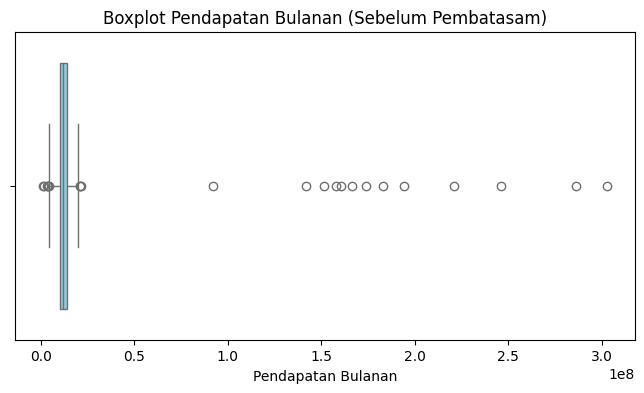

Q1: 10192000.00, Q3: 14100250.00 , IQR: 3908250.00
Batas Bawah: 4329625.00
Batas Atas: 19962625.00


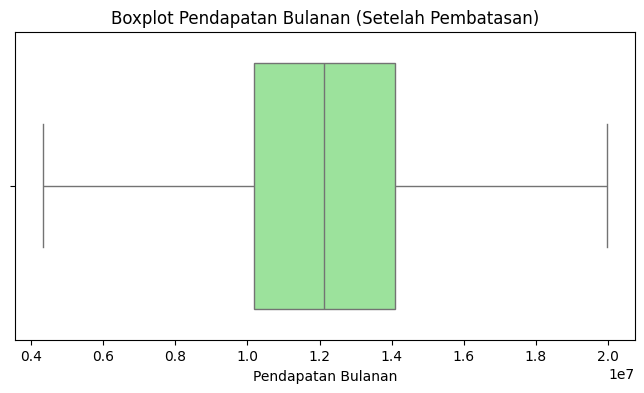

In [6]:
# 1. Visualisasi Box Plot untuk fitur Pendapatan_Bulanan
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'], color='skyblue')
plt.title('Boxplot Pendapatan Bulanan (Sebelum Pembatasam)')
plt.xlabel('Pendapatan Bulanan')
plt.show()

# 2. Hitung ambang batas menggunakan metode Interquartile Range (IQR)
Q1 = df_merged['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df_merged['Pendapatan_Bulanan'].quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}, Q3: {Q3:.2f} , IQR: {IQR:.2f}")
print(f"Batas Bawah: {batas_bawah:.2f}")
print(f"Batas Atas: {batas_atas:.2f}")

# 3. Membatasi nilai ekstrem tanpa membuang baris
df_merged['Pendapatan_Bulanan'] = np.where(
    df_merged['Pendapatan_Bulanan'] > batas_atas, batas_atas,
    np.where(df_merged['Pendapatan_Bulanan'] < batas_bawah, batas_bawah, df_merged['Pendapatan_Bulanan'])
)

# Visualisasi ulang setelah Capping
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_merged['Pendapatan_Bulanan'], color='lightgreen')
plt.title('Boxplot Pendapatan Bulanan (Setelah Pembatasan)')
plt.xlabel('Pendapatan Bulanan')
plt.show()

JAWABAN E-4:

Jika baris data dihapus hanya karena ada outlier, jumlah data kita akan berkurang dan informasi penting pada kolom lainnya ikut terbuang. Padahal dalam kasus gagal bayar, data dengan nilai ekstrem (seperti pendapatan yang sangat tinggi atau sangat rendah) justru memuat petunjuk penting tentang perilaku risiko nasabah. Menghapus data tersebut bisa membuat hasil analisis menjadi tidak seimbang (bias) dan tidak menggambarkan kondisi dunia nyata yang sebenarnya.

In [7]:
# 1. Ordinal Encoding pada kolom Tingkat_Pendidikan
map_pendidikan = {'SMA': 1, 'Sarjana': 2, 'Magister': 3}
df_merged['Tingkat_Pendidikan'] = df_merged['Tingkat_Pendidikan'].map(map_pendidikan)

# 2. Binary Mapping (0 dan 1) pada kolom biner Pernah_Gagal_Bayar_Lain
map_biner = {'Ya': 1, 'Tidak': 0, 'Y': 1, 'N': 0, 1: 1, 0: 0}
df_merged['Pernah_Gagal_Bayar_Lain'] = df_merged['Pernah_Gagal_Bayar_Lain'].map(map_biner)

# 3. One-Hot Encoding pada kolom Status_Pernikahan (drop_first=True)
df_encoded = pd.get_dummies(df_merged, columns=['Status_Pernikahan'], drop_first=True, dtype=int)

# 4. Hapus kolom identifier (ID_Pelanggan) dan kolom non-fitur yang tidak diperlukan
if 'ID_Pelanggan' in df_encoded.columns:
    df_encoded = df_encoded.drop(columns=['ID_Pelanggan'])

print("=== Kolom Dataset Setelah Encoding ===")
print(df_encoded.columns.tolist())
df_encoded.head()

=== Kolom Dataset Setelah Encoding ===
['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Tingkat_Pendidikan', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Pernah_Gagal_Bayar_Lain', 'Jumlah_Kartu_Kredit', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1


In [8]:
# 1. Pisahkan fitur prediktor (X) dan target (y = Status_Default)
X = df_encoded.drop(columns=['Status_Default'])
y = df_encoded['Status_Default']

# Fitur numerik kontinu yang akan distandarisasi
fitur_numerik = ['Usia', 'Pendapatan_Bulanan', 'Lama_Bekerja_Thn']

# 3. Ringkasan statistik (.describe()) sebelum standarisasi
print("=== Ringkasan Statistik Sebelum Standarisasi ===")
display(X[fitur_numerik].describe())

# 2. Transformasi Standardization (Z-score) pada variabel numerik
scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[fitur_numerik] = scaler.fit_transform(X[fitur_numerik])

# 3. Ringkasan statistik (.describe()) setelah standarisasi
print("\n=== Ringkasan Statistik Setelah Standarisasi ===")
display(X_scaled[fitur_numerik].describe())

# Menggabungkan kembali X yang telah diproses dengan target y untuk disimpan
df_clean_final = X_scaled.copy()
df_clean_final['Status_Default'] = y.values

# Simpan hasil akhir data bersih
df_clean_final.to_csv('clean_nasabah_final.csv', index=False)
print("\nDataset berhasil dibersihkan dan disimpan.")

=== Ringkasan Statistik Sebelum Standarisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.000000,1.000000e+03,1000.000000
mean,40.082000,1.212750e+07,12.948000
std,11.580128,3.062611e+06,6.689996
min,20.000000,4.329625e+06,1.000000
25%,30.000000,1.019200e+07,8.000000
50%,41.000000,1.213200e+07,13.000000
75%,50.000000,1.410025e+07,19.000000
max,59.000000,1.996262e+07,24.000000



=== Ringkasan Statistik Setelah Standarisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,-7.105427e-17,3.552714e-18,-5.684342e-17
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.735045e+00,-2.547425e+00,-1.786844e+00
25%,-8.710650e-01,-6.322922e-01,-7.399818e-01
50%,7.931340e-02,1.471131e-03,7.776689e-03
75%,8.568957e-01,6.444632e-01,9.050869e-01
max,1.634478e+00,2.559596e+00,1.652845e+00



Dataset berhasil dibersihkan dan disimpan.
